# 03 · Estratégia de cupons — Boto Café ☕🐬

**Objetivo:** transformar os segmentos RFM em **ações concretas** e **simular o custo × retorno** de cada uma,
com premissas explícitas que você pode editar. No fim, exportamos as listas de campanha (um CSV por segmento).

> **Analogia:** o RFM foi o *diagnóstico* (quem está saudável, quem está esfriando). Este notebook é a *receita médica*:
> cada paciente recebe um tratamento diferente e, antes de comprar o remédio, calculamos quanto ele custa e se compensa.
> Dar o mesmo cupom para todo mundo seria como dar o mesmo remédio a todos os pacientes.

⚠️ **Honestidade:** os dados são fictícios e as taxas de resposta são **hipóteses**, não medições.
Em uma loja real, você as trocaria por resultados de testes A/B.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import rfm as R, cupons as C

CAFE, ROSA, VERDE, CREME, OURO = "#3E2723", "#E8A0B4", "#2E5E4E", "#F5EDE0", "#C8963E"
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

rfm, base, data_ref = R.construir_rfm()
print(f"{len(rfm):,} clientes com RFM · data de referência {data_ref:%d/%m/%Y}")

1,981 clientes com RFM · data de referência 08/10/2026


## 1. De onde vem a margem? (do custo real dos produtos)
Desconto só faz sentido se sobrar lucro. Por isso calculamos a **margem bruta real** a partir do custo de cada produto,
em vez de chutar um número.

In [2]:
margem = C.calcular_margem(base)
print(f"Margem bruta global: {margem:.1%}  (de cada R$ 100 vendidos a preço de lista, R$ {margem*100:.0f} sobram depois do custo do produto)")

Margem bruta global: 48.4%  (de cada R$ 100 vendidos a preço de lista, R$ 48 sobram depois do custo do produto)


**Regra de ouro do desconto.** Em cada ação, o lucro líquido vem de:

`lucro = pedidos × ticket × (incremental × margem − desconto) − brindes − contato`

- **incremental** = fatia dos pedidos que só aconteceram por causa do cupom. O resto (quem compraria de qualquer jeito)
  ganha desconto "de graça": isso é **canibalização**, um custo que muita campanha esquece.
- Logo, o cupom só compensa quando `incremental × margem > desconto`.
  Com margem de ~48%, um cupom de 20% exige que **mais de ~41%** dos pedidos sejam realmente novos.

## 2. Uma ação por segmento
Cada segmento recebe uma ação, um cupom (códigos **novos**, que não reutilizam os históricos) e as hipóteses de resposta.
Para alterar uma premissa, edite o dicionário `PREMISSAS` em `src/cupons.py` e rode o notebook de novo.

In [3]:
acoes = pd.DataFrame([
    {"segmento": s, "ação": p.acao, "cupom": p.cupom, "desconto": f"{p.desconto:.0%}",
     "resposta": f"{p.taxa_resposta:.0%}", "incremental": f"{p.incremental:.0%}", "objetivo": p.objetivo}
    for s, p in C.PREMISSAS.items()]).set_index("segmento")
acoes

,ação,cupom,desconto,resposta,incremental,objetivo
segmento,,,,,,
Campeões,Recompensa sem desconto: brinde exclusivo + acesso antecipado a lançamentos,—,0%,60%,15%,Proteger quem sustenta a receita sem ensiná-los a esperar desconto.
Clientes Fiéis,Cupom leve de agradecimento na próxima compra,FIEL5,5%,35%,25%,"Manter o hábito; boa parte compraria de qualquer forma, então desconto baixo."
Potenciais Fiéis,"Cupom para a 3ª/4ª compra, acelerando o hábito",VOLTA10,10%,30%,50%,Estão a um passo de virar fiéis: vale empurrar.
Novos,"Cupom de segunda compra, enviado ~15 dias após a primeira",SEGUNDA10,10%,25%,60%,A 2ª compra é o grande divisor entre cliente e curioso.
Promissores,Cupom de reativação leve com sugestão de produto,PROMESSA10,10%,20%,60%,Compraram pouco e há pouco tempo: ainda dá para engajar.
Precisam de Atenção,Lembrete personalizado com cupom moderado,ATENCAO10,10%,20%,60%,Meio-termo que pode escorregar para o churn se ninguém olhar.
Prestes a Dar Churn,"Campanha 'saudade': cupom forte, contato pessoal (WhatsApp) para os de maior...",SAUDADE20,20%,20%,85%,Já foram bons clientes e concentram o maior valor em risco.
Hibernando,Cupom de retorno com prazo curto,SAUDADE15,15%,10%,90%,"Sumindo, mas com histórico: tentativa de custo controlado."
Perdidos,Último chamado por e-mail (custo baixo); sem investimento em desconto alto,ULTIMO15,15%,3%,95%,"Chance baixa: testar barato e, se não responderem, tirar da lista."


**Por que essas escolhas?**
- **Campeões não ganham desconto**: eles já compram sempre (só ~15% é incremental). Desconto os ensinaria a esperar promoção.
  Ganham *reconhecimento* (brinde, acesso antecipado), que custa pouco e protege o relacionamento.
- **Quanto mais esfriando, mais forte o cupom**: em "Prestes a Dar Churn" quase todo pedido é incremental (~85%),
  então um desconto de 20% se paga.
- **Perdidos recebem só um teste barato**: baixa chance de resposta, então o custo precisa ser mínimo.

## 3. Simulação de custo × retorno (cenário base)

In [4]:
sim = C.simular(rfm, margem)
tabela = sim[["clientes", "respondem", "custo_total", "margem_incremental", "lucro_liquido", "roi"]].copy()
tabela.loc["TOTAL"] = [tabela["clientes"].sum(), tabela["respondem"].sum(), tabela["custo_total"].sum(),
                       tabela["margem_incremental"].sum(), tabela["lucro_liquido"].sum(),
                       tabela["lucro_liquido"].sum() / tabela["custo_total"].sum()]
tabela

,clientes,respondem,custo_total,margem_incremental,lucro_liquido,roi
segmento,,,,,,
Campeões,201.00,120.60,"1,507.50","2,790.29","1,282.79",0.85
Clientes Fiéis,457.00,159.95,"2,009.51","4,535.64","2,526.12",1.26
Potenciais Fiéis,221.00,66.30,"1,550.81","3,596.00","2,045.19",1.32
Novos,68.00,17.00,310.15,842.24,532.09,1.72
Promissores,133.00,26.60,635.00,"1,729.85","1,094.85",1.72
Precisam de Atenção,108.00,21.60,473.26,"1,281.51",808.25,1.71
Prestes a Dar Churn,322.00,64.40,"4,311.26","8,677.96","4,366.70",1.01
Hibernando,170.00,17.00,690.90,"1,860.09","1,169.18",1.69
Perdidos,301.00,9.03,346.16,785.05,438.89,1.27


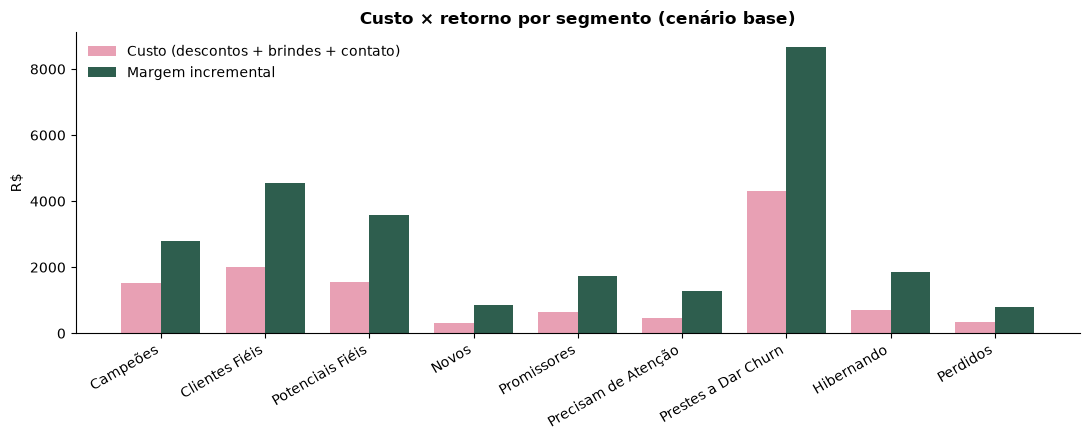

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(sim)); w = 0.38
ax.bar(x - w/2, sim["custo_total"], w, color=ROSA, label="Custo (descontos + brindes + contato)")
ax.bar(x + w/2, sim["margem_incremental"], w, color=VERDE, label="Margem incremental")
ax.set_xticks(x); ax.set_xticklabels(sim.index, rotation=30, ha="right")
ax.set_ylabel("R$"); ax.set_title("Custo × retorno por segmento (cenário base)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Como ler:** onde a barra verde supera a rosa, a ação dá lucro. Repare que "Prestes a Dar Churn" tem o **maior lucro absoluto** (muitos clientes × alto incremental),
mas o **menor ROI entre os grupos com cupom** (~1,0): o desconto de 20% é o mais caro. Já Novos, Promissores e Atenção
rendem mais por real investido (~1,7), porém em volumes pequenos.

> **Limite desta conta:** ela mede o lucro de **uma** campanha (poucos pedidos por cliente). O valor de longo prazo de um
> cliente que *volta a ser fiel* é bem maior (na Fase 2 estimamos ~R$ 849 mil/ano de potencial nos grupos em risco),
> mas depende de hipóteses ainda mais fortes. Aqui preferi o cálculo conservador.

## 4. O desconto de cada cupom é seguro? (ponto de equilíbrio)
Comparamos o desconto proposto com o **máximo** que cada segmento aguenta antes de dar prejuízo (`incremental × margem`).

In [6]:
eq = pd.DataFrame({
    "desconto proposto": [p.desconto for p in C.PREMISSAS.values()],
    "desconto máximo (equilíbrio)": [C.desconto_ponto_equilibrio(p, margem) for p in C.PREMISSAS.values()],
}, index=list(C.PREMISSAS))
eq["folga"] = eq["desconto máximo (equilíbrio)"] - eq["desconto proposto"]
eq.style.format("{:.1%}")

,desconto proposto,desconto máximo (equilíbrio),folga
Campeões,0.0%,7.3%,7.3%
Clientes Fiéis,5.0%,12.1%,7.1%
Potenciais Fiéis,10.0%,24.2%,14.2%
Novos,10.0%,29.1%,19.1%
Promissores,10.0%,29.1%,19.1%
Precisam de Atenção,10.0%,29.1%,19.1%
Prestes a Dar Churn,20.0%,41.2%,21.2%
Hibernando,15.0%,43.6%,28.6%
Perdidos,15.0%,46.0%,31.0%


Folga positiva = a ação tem margem de segurança. Quanto menor a folga, mais ela depende de a hipótese de
"incremental" estar certa. Na prática, a folga é o que mais deve ser **testado** antes de escalar.

## 5. E se as hipóteses estiverem erradas? (análise de sensibilidade)
**5.1 Cenários.** Multiplicamos a taxa de resposta (e reduzimos o incremental no pessimista) em todos os segmentos.

In [7]:
def cenario(mult_resposta: float, mult_incremental: float = 1.0) -> pd.DataFrame:
    prem = {s: replace(p, taxa_resposta=min(p.taxa_resposta * mult_resposta, 1.0),
                       incremental=min(p.incremental * mult_incremental, 1.0))
            for s, p in C.PREMISSAS.items()}
    return C.simular(rfm, margem, prem)

cenarios = {"Pessimista (resposta -50%, incremental -20%)": cenario(0.5, 0.8),
            "Base": cenario(1.0),
            "Otimista (resposta +50%)": cenario(1.5)}
pd.DataFrame({nome: {"custo total": s["custo_total"].sum(), "lucro líquido": s["lucro_liquido"].sum(),
                     "ROI": s["lucro_liquido"].sum() / s["custo_total"].sum()}
              for nome, s in cenarios.items()}).T

,custo total,lucro líquido,ROI
"Pessimista (resposta -50%, incremental -20%)","6,214.43","4,225.02",0.68
Base,"11,834.56","14,264.06",1.21
Otimista (resposta +50%),"17,454.68","21,693.25",1.24


**5.2 Zoom no segmento mais importante:** "Prestes a Dar Churn". Qual combinação de *desconto × % de pedidos realmente incrementais* dá lucro? (O incremental é a hipótese mais difícil de acertar.)

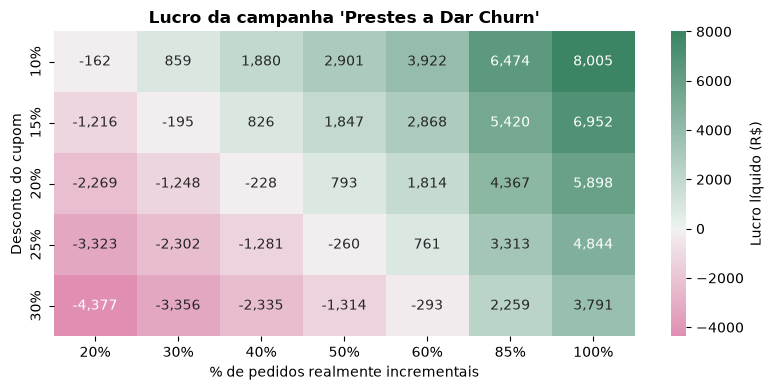

In [8]:
seg = "Prestes a Dar Churn"
descontos = [0.10, 0.15, 0.20, 0.25, 0.30]
incrementais = [0.20, 0.30, 0.40, 0.50, 0.60, 0.85, 1.00]
grade = pd.DataFrame(
    [[C.simular(rfm, margem, {**C.PREMISSAS, seg: replace(C.PREMISSAS[seg], desconto=d, incremental=r)})
       .at[seg, "lucro_liquido"] for r in incrementais] for d in descontos],
    index=[f"{d:.0%}" for d in descontos], columns=[f"{r:.0%}" for r in incrementais])

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(grade, annot=True, fmt=",.0f", cmap=sns.diverging_palette(350, 150, as_cmap=True), center=0,
            cbar_kws={"label": "Lucro líquido (R$)"}, ax=ax)
ax.set_xlabel("% de pedidos realmente incrementais"); ax.set_ylabel("Desconto do cupom")
ax.set_title(f"Lucro da campanha '{seg}'")
plt.tight_layout(); plt.show()

**Leitura:** as células vermelhas são prejuízo. Quanto maior o desconto, mais incremental é preciso para compensar
(ponto de equilíbrio = desconto ÷ margem). Se na prática metade dos "resgates" viesse de quem já voltaria sozinho,
o cupom de 20% ficaria no limite. Por isso se **testa com grupo de controle** antes de disparar para todos.

## 6. Listas de campanha (para entregar ao time de marketing)
Uma linha por cliente, com **segmento, cupom sugerido, ação e o motivo** (um texto curto e personalizado).
Geramos um CSV por segmento e um consolidado em `data/campanhas/` (codificação `utf-8-sig`, que o Excel abre com acentos corretos).

In [9]:
camp = C.montar_campanha(rfm)
arquivos = C.exportar_campanhas(camp)
for a in arquivos:
    print(f"{a.name:<38} {sum(1 for _ in open(a, encoding='utf-8-sig')) - 1:>5} linhas")

campanha_campeoes.csv                    201 linhas
campanha_clientes_fieis.csv              457 linhas
campanha_potenciais_fieis.csv            221 linhas
campanha_novos.csv                        68 linhas
campanha_promissores.csv                 133 linhas
campanha_precisam_de_atencao.csv         108 linhas
campanha_prestes_a_dar_churn.csv         322 linhas
campanha_hibernando.csv                  170 linhas
campanha_perdidos.csv                    301 linhas
campanha_completa.csv                   1981 linhas


In [10]:
camp[camp['segmento'] == 'Prestes a Dar Churn'].head(5)[['cliente', 'nome', 'estado', 'cupom_sugerido', 'gasto_total', 'motivo']]

,cliente,nome,estado,cupom_sugerido,gasto_total,motivo
1239,1245,Lunna Fernandes Cirino,AM,SAUDADE20,"5,010.98","Prestes a Dar Churn: 10 pedido(s), R$ 5,011 gastos, última compra há 169 dia..."
1122,1128,Luiz Fernando Santos Novais,SC,SAUDADE20,"4,178.72","Prestes a Dar Churn: 11 pedido(s), R$ 4,179 gastos, última compra há 175 dia..."
233,234,Maria Júlia Andrade Cavalcanti,AC,SAUDADE20,"3,901.74","Prestes a Dar Churn: 9 pedido(s), R$ 3,902 gastos, última compra há 152 dias..."
583,587,Benjamim Pereira Ribeiro,PE,SAUDADE20,"3,426.50","Prestes a Dar Churn: 9 pedido(s), R$ 3,426 gastos, última compra há 157 dias..."
1032,1038,Anthony Moura Sousa,SP,SAUDADE20,"3,392.38","Prestes a Dar Churn: 7 pedido(s), R$ 3,392 gastos, última compra há 194 dias..."


**Prioridade de contato:** dentro de cada lista, os clientes vêm ordenados por **gasto total** (os de maior valor primeiro).
Em "Prestes a Dar Churn", os primeiros ~200 concentram 80% do valor em risco: é onde um contato **pessoal** (WhatsApp) faz mais sentido.

## 7. Resumo e limitações
| O que fizemos | Resultado |
|---|---|
| Margem real a partir do custo dos produtos | ~48% |
| Ação por segmento, com cupons novos | 9 ações; Campeões sem desconto |
| Simulação custo × retorno | positiva no cenário base; sensível à taxa de resposta |
| Listas de campanha | `data/campanhas/*.csv` |

**Limitações honestas**
1. Taxas de resposta e "incremental" são **hipóteses**; o certo é medi-las com teste A/B (grupo com cupom × grupo de controle).
2. A simulação mede **uma** campanha; não inclui valor de longo prazo nem fadiga de e-mail.
3. A margem é a média da loja; o lucro real varia por produto/categoria.
4. Os dados são sintéticos, então os números servem para **mostrar o método**, não para prever uma loja real.